In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def load_data(file):
    my_data = np.loadtxt(file, delimiter=',')
    return my_data[:, :-1], my_data[:, -1, None].astype(int)

In [3]:
def to_one_hot(y, k):
    n = y.shape[0]
    one_hot_y = np.zeros((n, k))
    one_hot_y[np.arange(n), y.flatten()] = 1
    return one_hot_y

In [4]:
def softmax(z):
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [5]:
def train_simple(X, y, k, lr=1e-3, epochs=20000, tol=1e-8):
    m, n = X.shape
    W = np.zeros((n, k))
    b = np.zeros((1, k))
    one_hot_y = to_one_hot(y, k)
    for epoch in range(epochs):
        z = X @ W + b
        y_hat = softmax(z)
        error = y_hat - one_hot_y
        dw = X.T @ error
        db = np.sum(error, axis=0, keepdims=True)
        if np.linalg.norm(dw) <= tol:
            print(f'GD converged in {epoch} steps')
            break
        W -= (lr / m) * dw
        b -= (lr / m) * db
    return W, b

In [6]:
def solve_normal_equation(X, y, k):
    Y = to_one_hot(y, k)
    xt_x = X.T @ X
    xt_y = X.T @ Y
    W = np.linalg.inv(xt_x) @ xt_y
    return W

In [7]:
def rbf_kernel_calculator(X, X_prime, params):
    if "sigma" not in params:
        raise ValueError("missing expected params")
    sigma = params["sigma"]
    diff = X[:, None, :] - X_prime[None, :, :]
    norm = np.linalg.norm(diff, axis=-1)**2
    return np.exp((-1 * norm) / (2 * sigma**2))

In [8]:
def laplace_kernel_calculator(X, X_prime, params):
    if "sigma" not in params:
        raise ValueError("missing expected params")
    sigma = params["sigma"]
    diff = X[:, None, :] - X_prime[None, :, :]
    norm = np.linalg.norm(diff, axis=-1, ord=1)
    return np.exp((-1 * norm) / sigma)

In [9]:
def polynomial_kernel_calculator(X, X_prime, params):
    if "c" not in params or "d" not in params:
        raise ValueError("missing expected params")
    c, d = params["c"], params["d"]
    poly = X @ X_prime.T + c
    return poly**d

In [10]:
def solve_ridge(X, X_prime, y, k, kernel_calculator, params):
    Y = to_one_hot(y, k)
    m, n = X.shape
    K = kernel_calculator(X, X_prime, params)
    lambda_reg = params["lambda"]
    alpha = np.linalg.inv(K + lambda_reg * np.eye(m)) @ Y
    return alpha

In [11]:
def plot_data(unique_values, counts):
    plt.figure(figsize=(8, 5))
    plt.bar(unique_values, counts, color='skyblue')
    plt.xlabel('Labels')
    plt.ylabel('Count')
    plt.title('Label Distribution')
    plt.savefig('label_distribution.png', dpi=300)
    plt.show()


Training Class Distribution: {3: 8, 4: 38, 5: 460, 6: 460, 7: 141, 8: 8}



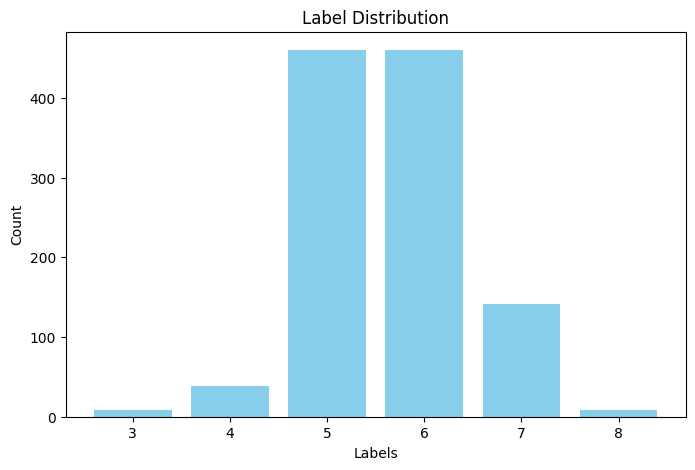

running simple regression solver
success: 252, fail:227, success_percent:0.5260960334029228

--- Starting RBF Grid Search ---
Best RBF Params: {'lambda': 1, 'sigma': 1} (CV Accuracy: 0.6413)
Evaluating winning RBF model on Test Set...
success: 289, fail:190, success_percent:0.6033402922755741

--- Starting Laplace Grid Search ---
Best Laplace Params: {'lambda': 0.1, 'sigma': 1} (CV Accuracy: 0.6735)
Evaluating winning Laplace model on Test Set...
success: 307, fail:172, success_percent:0.6409185803757829

--- Starting Polynomial Grid Search ---
Best Polynomial Params: {'lambda': 10, 'c': 1, 'd': 3} (CV Accuracy: 0.6054)
Evaluating winning Polynomial model on Test Set...
success: 288, fail:191, success_percent:0.6012526096033403

Evaluating RBF kernel on new batch
[7 5 5 7 7]
Evaluating Laplace kernel on new batch
[7 5 5 7 7]
Evaluating Polynomial kernel on new batch
[6 4 5 6 6]


In [12]:
def run_train_test(train_fn, train_X, train_Y, test_X, test_Y):
    W, b = train_fn(train_X, train_Y, 10, 1e-3, 30000, 1e-6)

    z = test_X @ W + b
    y_hat = softmax(z)
    y_pred = np.argmax(y_hat, axis=1).astype(int)
    
    success = np.sum(y_pred == test_Y.flatten())
    fail = np.sum(y_pred != test_Y.flatten())
    print(f'success: {success}')
    print(f'fail: {fail}')

def run_affine_classifier_simple(normal_eq_solver, train_X, train_Y, test_X, test_Y):
    m_train, n_train = train_X.shape
    train_X = np.hstack((np.ones((m_train, 1)), train_X))
    m_test, n_test = test_X.shape
    test_X = np.hstack((np.ones((m_test, 1)), test_X))
    W = normal_eq_solver(train_X, train_Y, 10)
    z = test_X @ W
    y_pred = np.argmax(z, axis=1).astype(int)
    
    success = np.sum(y_pred == test_Y.flatten())
    fail = np.sum(y_pred != test_Y.flatten())
    print(f'success: {success}, fail:{fail}, success_percent:{success/ (success + fail)}')

def run_ridge_classifier(ridge_eq_solver, train_X, train_Y, test_X, test_Y, kernel_calculator, params):
    alpha = ridge_eq_solver(train_X, train_X, train_Y, 10, kernel_calculator, params)
    m_train, n_train = train_X.shape
    m_test, n_test = test_X.shape
    success, fail = 0, 0
    K_test = kernel_calculator(test_X, train_X, params)
    y_hat = K_test @ alpha
    y_pred = np.argmax(y_hat, axis=1)
    success = np.sum(y_pred == test_Y.flatten())
    fail = np.sum(y_pred != test_Y.flatten())
    print(f'success: {success}, fail:{fail}, success_percent:{success/ (success + fail)}')

def ridge_classifier_unseen(ridge_eq_solver, train_X, train_Y, test_X, kernel_calculator, params):
    alpha = ridge_eq_solver(train_X, train_X, train_Y, 10, kernel_calculator, params)
    m_train, n_train = train_X.shape
    m_test, n_test = test_X.shape
    K_test = kernel_calculator(test_X, train_X, params)
    y_hat = K_test @ alpha
    y_pred = np.argmax(y_hat, axis=1)
    return y_pred

def k_fold_cross_validation(X, Y, k_folds, ridge_eq_solver, kernel_calculator, params):
    m = X.shape[0]
    fold_size = m // k_folds
    indices = np.arange(m)
    np.random.shuffle(indices)
    
    accuracies = []
    
    for i in range(k_folds):
        val_start = i * fold_size
        val_end = (i + 1) * fold_size if i != k_folds - 1 else m
        val_idx = indices[val_start:val_end]
        train_idx = np.concatenate((indices[:val_start], indices[val_end:]))
        X_train_fold, Y_train_fold = X[train_idx], Y[train_idx]
        X_val_fold, Y_val_fold = X[val_idx], Y[val_idx]
        alpha = ridge_eq_solver(X_train_fold, X_train_fold, Y_train_fold, 10, kernel_calculator, params)
        K_val = kernel_calculator(X_val_fold, X_train_fold, params)
        y_hat = K_val @ alpha
        y_pred = np.argmax(y_hat, axis=1)
        success = np.sum(y_pred == Y_val_fold.flatten())
        accuracies.append(success / len(val_idx))
        
    return np.mean(accuracies)
    
train_X, train_Y  = load_data('wine_training.csv')
test_X, test_Y = load_data('wine_test.csv')
train_mean_X = np.mean(train_X, axis=0)
train_std_dev_X = np.std(train_X, axis=0)
train_X = (train_X - train_mean_X) / train_std_dev_X
test_X = (test_X - train_mean_X) / train_std_dev_X

unique_values, counts = np.unique(train_Y[:, 0], return_counts=True)
print(f"\nTraining Class Distribution: {dict(zip(unique_values, counts))}")
print()
plot_data(unique_values, counts)

#print(f'running simple training')
#run_train_test(train_simple, train_X, train_Y, test_X, test_Y)

print(f'running simple regression solver')
run_affine_classifier_simple(solve_normal_equation, train_X, train_Y, test_X, test_Y)
print()

k_folds = 5
lambdas = [1e-4, 1e-2, 0.1, 1, 10]
rbf_sigmas = [0.1, 0.5, 1, 2, 3, 5]
laplace_sigmas = [1, 5, 10, 20]
polynomial_degrees = [2, 3, 4]

# --- RBF Grid Search ---
print("--- Starting RBF Grid Search ---")
best_rbf_score, best_rbf_params = 0, {}
for lambda_reg in lambdas:
    for sigma in rbf_sigmas:
        params = {"lambda": lambda_reg, "sigma": sigma}
        score = k_fold_cross_validation(train_X, train_Y, k_folds, solve_ridge, rbf_kernel_calculator, params)
        if score > best_rbf_score:
            best_rbf_score = score
            best_rbf_params = params.copy()

print(f"Best RBF Params: {best_rbf_params} (CV Accuracy: {best_rbf_score:.4f})")
print("Evaluating winning RBF model on Test Set...")
run_ridge_classifier(solve_ridge, train_X, train_Y, test_X, test_Y, rbf_kernel_calculator, best_rbf_params)


# --- Laplace Grid Search ---
print("\n--- Starting Laplace Grid Search ---")
best_laplace_score, best_laplace_params = 0, {}
for lambda_reg in lambdas:
    for sigma in laplace_sigmas:
        params = {"lambda": lambda_reg, "sigma": sigma}
        score = k_fold_cross_validation(train_X, train_Y, k_folds, solve_ridge, laplace_kernel_calculator, params)
        if score > best_laplace_score:
            best_laplace_score = score
            best_laplace_params = params.copy()

print(f"Best Laplace Params: {best_laplace_params} (CV Accuracy: {best_laplace_score:.4f})")
print("Evaluating winning Laplace model on Test Set...")
run_ridge_classifier(solve_ridge, train_X, train_Y, test_X, test_Y, laplace_kernel_calculator, best_laplace_params)


# --- Polynomial Grid Search ---
print("\n--- Starting Polynomial Grid Search ---")
best_poly_score, best_poly_params = 0, {}
for lambda_reg in lambdas:
    for d in polynomial_degrees:
        params = {"lambda": lambda_reg, "c": 1, "d": d}
        score = k_fold_cross_validation(train_X, train_Y, k_folds, solve_ridge, polynomial_kernel_calculator, params)
        if score > best_poly_score:
            best_poly_score = score
            best_poly_params = params.copy()

print(f"Best Polynomial Params: {best_poly_params} (CV Accuracy: {best_poly_score:.4f})")
print("Evaluating winning Polynomial model on Test Set...")
run_ridge_classifier(solve_ridge, train_X, train_Y, test_X, test_Y, polynomial_kernel_calculator, best_poly_params)

print()
unseen_data = np.loadtxt('wine_new_batch.csv', delimiter=',')
unseen_data = (unseen_data - train_mean_X) / train_std_dev_X
print('Evaluating RBF kernel on new batch')
print(ridge_classifier_unseen(solve_ridge, train_X, train_Y, unseen_data, rbf_kernel_calculator, best_rbf_params))
print('Evaluating Laplace kernel on new batch')
print(ridge_classifier_unseen(solve_ridge, train_X, train_Y, unseen_data, laplace_kernel_calculator, best_laplace_params))
print('Evaluating Polynomial kernel on new batch')
print(ridge_classifier_unseen(solve_ridge, train_X, train_Y, unseen_data, polynomial_kernel_calculator, best_poly_params))